# Estrategia USD/CLP con tamaño de posición calibrado
## Torneo Data Science en Finanzas — FEN Universidad de Chile · Banco Itaú 2026

**Participante:** Martín Valenzuela · **Entrega:** jueves 12 de noviembre de 2026 · **Base:** `data/base_usdclp.xlsx` (extracción Bloomberg del laboratorio, 2026-10-07)

Este notebook contiene lo solicitado por el laboratorio para la entrega, en este orden:

| Sección | Contenido | Punto de la pauta |
|---|---|---|
| 1 | Resumen del backtesting y estadísticas de trading | Notebook |
| 2 | Supuestos clave | Modelos y supuestos |
| 3 | Modelos utilizados y cómo se combinan | Modelos y supuestos |
| 4 | Datos y calendario de jornadas | — |
| 5 | Evidencia del efecto de calendario (variable adicional documentada) | — |
| 6 | Backtest: curvas, retornos por año, caídas | Notebook |
| 7 | Pruebas estadísticas (Diebold-Mariano, bootstrap) y sensibilidad a costos y parámetros | Notebook |
| 8 | Lectura de la convicción | Entregable 3 de las bases |
| 9 | Mecanismo de ejecución, señal del día y calendario del período de monitoreo | Mecanismo de ejecución |
| 10 | Riesgos, limitaciones y reproducibilidad | — |

**Cómo ejecutarlo:** desde la raíz del repositorio, `jupyter notebook estrategia_usdclp.ipynb` y luego *Kernel ▸ Restart & Run All* (≈ 2 minutos). Requiere `pip install -r requirements.txt` y la base en `data/base_usdclp.xlsx`. Todas las cifras, tablas y gráficos se recalculan desde la base al ejecutar; ninguna está escrita a mano. Los mismos cálculos están disponibles como scripts (`scripts/run_final.py`, `scripts/predict_next.py`) y pruebas automáticas (`tests/test_no_leakage.py`).

In [2]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# raíz del repositorio = la carpeta que contiene src/torneo (funciona si el notebook se abre desde la raíz o desde una subcarpeta)
RAIZ = os.getcwd()
while not os.path.isdir(os.path.join(RAIZ, "src", "torneo")):
    padre = os.path.dirname(RAIZ)
    if padre == RAIZ:
        raise FileNotFoundError("No encuentro src/torneo: abrir el notebook desde la raíz del repositorio")
    RAIZ = padre
sys.path.insert(0, os.path.join(RAIZ, "src"))
BASE = os.path.join(RAIZ, "data", "base_usdclp.xlsx")
REPORTS = os.path.join(RAIZ, "reports")

from torneo.data import PX, SERIES, cargar_base, dataset
from torneo.calendario import CATEGORIAS, categorizar, estrategia_calendario
from torneo.evaluate import COSTO_BASE_PB, pnl, referencias, resumen, tabla_costos
from torneo.stats import diebold_mariano, ic_bootstrap
from torneo.signal import FERIADOS_CL, calendario_esperado, generar_senal

pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 100

COSTO = COSTO_BASE_PB                              # 6 pb por unidad de cambio de exposición (laboratorio: 5–7 pb)
INICIO_REGLA = "2014-01-02"                        # desde cuándo opera la regla (antes no hay ≥ 60 observaciones por categoría)
INICIO_VAL, FIN_VAL = "2014-01-02", "2025-05-29"   # validación walk-forward
INICIO_TEST = "2025-05-30"                         # tramo final fuera de muestra, hasta el final de la base
print("Repositorio:", RAIZ)
print("Base:", BASE, "| existe:", os.path.exists(BASE))

Repositorio: C:\Users\marti\Downloads\UsdClp\usdclp_torneo_entrega\usdclp-torneo
Base: C:\Users\marti\Downloads\UsdClp\usdclp_torneo_entrega\usdclp-torneo\data\base_usdclp.xlsx | existe: True


## 1. Resumen del backtesting

**Qué hace la estrategia.** Compra dólar con exposición 1 en las rachas de jornadas con ventaja histórica —la última jornada antes de un fin de semana o feriado y el lunes siguiente— solo cuando la ventaja esperada acumulada de la racha cubre con margen el costo de la ida y vuelta, y se queda en pesos (ganando la tasa local) el resto del tiempo. Nunca usa exposición 3, porque la evidencia no lo justifica, y se apaga sola si el efecto desaparece de los datos.

**Por qué esa regla y no un modelo de machine learning.** Probamos once configuraciones (regresión logística, boosting de gradiente y regresión ridge; con variables macro, intradía y de calendario; horizontes de 1 y 5 jornadas) con walk-forward, purga y calibración rodante: ninguna distingue del azar (sección 3). El efecto de calendario es la única regularidad robusta en 2010 → 2025-05, aparece también en USD/MXN, USD/BRL y USD/COP (y no en el DXY) y tiene una explicación económica: una prima por el riesgo acumulado durante el fin de semana en monedas emergentes.

**Resultado en una línea.** Retorno similar al de "comprar siempre" con menos de la mitad de la caída máxima, en el mercado el 40 % de las jornadas. Nada es estadísticamente significativo con 341 jornadas fuera de muestra, y lo decimos.

**Advertencia de lectura.** La regla no operó entre 2014 y 2021: con 6 pb de costo un lunes aislado (≈ 11 pb de ventaja) no cubre el umbral de 15 pb por episodio, y la jornada previa al fin de semana solo cruzó los umbrales estadísticos de la ventana expansiva en 2022. El retorno de la validación se genera, por lo tanto, entre mayo de 2022 y mayo de 2025; la sección 6 muestra ese período activo por separado y la tabla anual deja a la vista los años en cero.

La celda siguiente carga la base, ejecuta la regla con ventana expansiva (re-estimación cada 21 jornadas, solo con información pasada) y calcula las estadísticas de trading de la estrategia y de las tres referencias de las bases, para la validación (2014 → 2025-05) y para el tramo final fuera de muestra (2025-05-30 → fin de la base). Todo en excedente sobre la tasa en pesos, neto de carry y de 6 pb por unidad de cambio de exposición.

In [3]:
# ---- carga, construcción del dataset y ejecución de la regla (walk-forward) ----
j, F = dataset(BASE, inicio="2009-01-01")
pos_wf, det_wf = estrategia_calendario(F, INICIO_REGLA, k1=0.0, k3=0.25, costo_bp=COSTO)

# dirección del modelo SIN filtro (signo de la media histórica de la categoría de la jornada objetivo): define la referencia
# "intensidad constante" (operar siempre con exposición 1) y el acierto direccional "sin apalancamiento"
p_dir = 0.5 + np.sign(det_wf["media_bruta_pb"].fillna(0)) * 0.1
direccion = np.sign(2 * p_dir - 1)


def tramo(a, b):
    m = (pos_wf.index >= a) & (pos_wf.index <= b) & F["ret_next"].notna()
    est = pnl(pos_wf[m], F, COSTO)
    refs = referencias(F, est.index, p_dir, COSTO)
    return est, refs


est_v, refs_v = tramo(INICIO_VAL, FIN_VAL)
est_f, refs_f = tramo(INICIO_TEST, "2030-01-01")

FILAS = [("retorno neto de carry y costos (%)", "neto_%"), ("retorno bruto (%)", "bruto_%"), ("carry pagado (%)", "carry_%"),
         ("costos de transacción (%)", "costos_%"), ("retorno total incl. tasa local (%)", "total_%"),
         ("retorno neto anualizado (%)", "neto_anual_%"), ("volatilidad anualizada (%)", "vol_anual_%"),
         ("Sharpe anualizado (excedente sobre la TPM)", "sharpe_neto_anual"), ("Sortino", "sortino_anual"),
         ("caída máxima (%)", "max_drawdown_%"), ("Calmar", "calmar"),
         ("% aciertos en jornadas operadas (sin apalancamiento)", "acierto_direccional_operado"),
         ("% aciertos ponderado por exposición (con apalancamiento)", "acierto_ponderado_exposicion"),
         ("% aciertos de la dirección sin filtro (todas las jornadas)", "acierto_direccional_total"),
         ("nº operaciones (cambios de exposición)", "n_operaciones"), ("nº episodios (entrada → salida)", "n_episodios"),
         ("jornadas con posición", "jornadas_operadas"), ("% jornadas fuera del mercado", "dias_fuera_%"),
         ("rotación total (unidades de exposición)", "turnover_unidades")]
PORCENTAJES = ["acierto_direccional_operado", "acierto_ponderado_exposicion", "acierto_direccional_total"]


def tabla_estadisticas(est, refs):
    cols = {"estrategia": resumen(est, direccion), **{k.replace("_", " "): resumen(v, direccion) for k, v in refs.items()}}
    t = pd.DataFrame(cols).astype(float)
    t.loc["carry_%"] = t.loc["bruto_%"] - t.loc["con_carry_%"]
    t.loc[PORCENTAJES] = t.loc[PORCENTAJES] * 100
    t = t.loc[[k for _, k in FILAS]]
    t.index = [n for n, _ in FILAS]
    return t.round(2)


tab_v, tab_f = tabla_estadisticas(est_v, refs_v), tabla_estadisticas(est_f, refs_f)
print(f"VALIDACIÓN walk-forward {est_v.index[0].date()} → {est_v.index[-1].date()} ({len(est_v)} jornadas)")
display(tab_v)
print(f"TRAMO FINAL fuera de muestra {est_f.index[0].date()} → {est_f.index[-1].date()} ({len(est_f)} jornadas)")
display(tab_f)

VALIDACIÓN walk-forward 2014-01-02 → 2025-05-29 (2878 jornadas)


,estrategia,comprar siempre,no operar,intensidad constante
retorno neto de carry y costos (%),29.03,38.86,0.00,45.62
retorno bruto (%),54.28,66.97,0.00,191.68
carry pagado (%),6.59,28.06,0.00,3.92
costos de transacción (%),18.66,0.06,0.00,142.14
retorno total incl. tasa local (%),77.01,86.84,47.98,93.60
retorno neto anualizado (%),2.54,3.40,0.00,3.99
volatilidad anualizada (%),5.66,12.56,0.00,12.48
Sharpe anualizado (excedente sobre la TPM),0.45,0.27,0.00,0.32
Sortino,0.66,0.39,NaN,0.45
caída máxima (%),-13.87,-33.43,0.00,-43.46


TRAMO FINAL fuera de muestra 2025-05-30 → 2026-10-05 (341 jornadas)


,estrategia,comprar siempre,no operar,intensidad constante
retorno neto de carry y costos (%),2.56,2.80,0.00,3.58
retorno bruto (%),11.42,3.89,0.00,20.73
carry pagado (%),0.58,1.02,0.00,0.17
costos de transacción (%),8.28,0.06,0.00,16.98
retorno total incl. tasa local (%),8.91,9.16,6.36,9.94
retorno neto anualizado (%),1.89,2.07,0.00,2.65
volatilidad anualizada (%),7.53,11.82,0.00,11.70
Sharpe anualizado (excedente sobre la TPM),0.25,0.18,0.00,0.23
Sortino,0.38,0.26,NaN,0.32
caída máxima (%),-5.78,-14.28,0.00,-13.67


Lectura de la tabla: la estrategia renuncia a parte del retorno de "comprar siempre" (está fuera del mercado la mayor parte del tiempo) a cambio de una caída máxima mucho menor y un Sharpe mayor; "intensidad constante" (operar siempre con exposición 1 en la dirección de la media histórica de cada categoría) rinde algo más en bruto, pero paga la rotación con costos reales y tiene la caída máxima de una posición permanente. Las pruebas de significancia están en la sección 7.

## 2. Supuestos clave

| Supuesto | Valor usado | Origen |
|---|---|---|
| Convención de información | Los cierres fechados t (toda la fila t de la base) deciden la posición de la jornada t+1; esa posición se paga con el retorno de t+1 | Diccionario del kick-off ("los valores de cierre de una misma fecha están todos disponibles al momento de decidir") |
| Precio | Cierre `USDCLP Curncy PX_LAST` de Bloomberg, cierre a cierre. No se usa la apertura ni el dólar observado: el observado publicado con fecha t corresponde al promedio de la jornada t−1 (verificado en la base) | Base; verificación en `reports/INFORME.md` §2 |
| Jornadas | Días con cierre USD/CLP. En feriados chilenos no hay jornada: la posición se mantiene y las tasas se devengan por días corridos, como el Índice de Cámara | Hipótesis (mercado de dinero chileno) |
| Resultado diario | `pos_t · (S_t+1/S_t − 1) − pos_t · carry_t+1 − c · |pos_t − pos_t−1|`, aditivo sobre un nocional fijo | Bases §2 |
| Carry | `(TPM − SOFR) / 360 · días corridos` por unidad de exposición (Fed funds efectiva antes de abril de 2018, cuando no existía SOFR). El largo en dólar paga el diferencial; el corto lo recibe | Hipótesis; bloque `carry_cl` del diccionario |
| Costos de transacción | c = 6 pb por unidad de cambio de exposición, centro del rango 5–7 pb indicado por el laboratorio; sensibilidad 0 a 10 pb en la sección 7 | Laboratorio (11-11-2026) |
| Tasa local y ajuste por riesgo | "No operar" gana la TPM devengada; todos los retornos se reportan como excedente sobre la TPM (y como total) y el Sharpe se calcula sobre ese excedente | Laboratorio: ajuste por riesgo con la tasa chilena |
| Referencias | Comprar siempre (+1 permanente), no operar nunca (0), intensidad constante (dirección del modelo sin filtro, exposición 1), con la misma regla de P&L | Bases §4 |
| Posiciones admitidas | {−3, −1, 0, 1, 3} | Bases §2 |
| Huecos de la base | Relleno hacia adelante solo por "mercado cerrado" (feriado de la plaza de la serie); series descontinuadas o rancias no se usan; nunca relleno hacia atrás | Diccionario, pregunta 5 |
| Variable adicional | Categoría de calendario de la jornada objetivo (lunes, pre fin de semana, post feriado, interior): pública y conocida de antemano | Laboratorio: documentar como variable adicional |

## 3. Modelos utilizados y cómo se combinan

### 3.1 Modelos de machine learning probados (resultado negativo, documentado)

Protocolo común: walk-forward con ventana expansiva desde 2018 hasta 2025-05, re-entrenamiento cada 21 jornadas, purga y embargo iguales al horizonte de la etiqueta, calibración de Platt rodante y comparación con el pronóstico ingenuo (probabilidad 0,5) mediante el puntaje de Brier y el test de Diebold-Mariano. Modelos: regresión logística regularizada, boosting de gradiente por histogramas y regresión ridge sobre el retorno estandarizado; conjuntos de variables base (retornos y volatilidad del USD/CLP, cobre, DXY, monedas emergentes, tasas), macro, intradía (apertura, máximo, mínimo, cierre de la jornada t) y calendario; horizontes de 1 y 5 jornadas. Ninguna configuración tiene habilidad probabilística demostrable: Brier ≈ 0,250 (igual que el ingenuo), AUC entre 0,47 y 0,55, p-valores de Diebold-Mariano > 0,10. Por eso **ningún modelo de ML forma parte de la estrategia final**. La tabla se regenera con `python scripts/run_backtest.py data/base_usdclp.xlsx reports` (≈ 1,5 minutos).

In [4]:
ruta_ml = os.path.join(REPORTS, "validacion_configs.csv")
if os.path.exists(ruta_ml):
    ml = pd.read_csv(ruta_ml).set_index("config")
    ml = ml[["n", "brier", "brier_naive", "auc", "acc", "DM_HLN_vs_naive", "p_valor", "neto_val_%", "sharpe_val", "fuera_val_%"]]
    ml.columns = ["jornadas", "Brier", "Brier ingenuo", "AUC", "acierto", "DM vs ingenuo", "p-valor", "neto validación (%)", "Sharpe", "% fuera"]
    display(ml.round(3))
else:
    print("reports/validacion_configs.csv no está: generar con  python scripts/run_backtest.py data/base_usdclp.xlsx reports")

,jornadas,Brier,Brier ingenuo,AUC,acierto,DM vs ingenuo,p-valor,neto validación (%),Sharpe,% fuera
config,,,,,,,,,,
h1_ridge_macro_cal,1376,0.248,0.25,0.548,0.543,-1.591,0.112,1.23,0.05,88.5
h1_logit_macro_cal,1376,0.249,0.25,0.535,0.512,-1.144,0.253,-2.35,-0.15,95.1
h1_ridge_cal,1376,0.249,0.25,0.536,0.524,-0.963,0.336,-8.79,-0.61,95.9
h1_ridge_macro,1376,0.250,0.25,0.523,0.513,-0.529,0.597,-6.04,-0.35,94.5
h1_ridge_intra,1376,0.250,0.25,0.521,0.507,-0.430,0.667,6.27,0.26,93.0
h1_hgb_base,1376,0.250,0.25,0.513,0.504,0.093,0.926,-3.55,-0.14,91.9
h1_logit_base,1376,0.250,0.25,0.511,0.514,0.130,0.896,-1.21,-0.09,97.5
h1_logit_macro,1376,0.250,0.25,0.504,0.496,0.192,0.848,-0.85,-0.14,99.1
h1_logit_intra,1376,0.250,0.25,0.502,0.483,0.232,0.816,-2.40,-0.35,99.3


### 3.2 Modelo de calendario (el que opera)

1. **Clasificación de la jornada objetivo** (t+1) con el calendario, conocido de antemano: `lunes` (primera jornada tras el fin de semana), `pre_finde` (la jornada siguiente a t+1 está a ≥ 3 días corridos: viernes o víspera de feriado), `post_feriado` (t+1 sigue a un salto de ≥ 3 días y no es lunes) o `interior`.
2. **Ventaja esperada por categoría** con ventana expansiva: con todas las jornadas desde 2009 cuya etiqueta ya se conoce, se estima para cada categoría la media y el estadístico t del retorno de la jornada. La tabla se re-estima cada 21 jornadas. Una categoría se **activa** cuando |t| > 2 y |media| > 5 pb y se **desactiva** cuando |t| < 1 (histéresis estadística, para no encender y apagar la señal con cada actualización). La ventaja esperada de una categoría inactiva es 0.
3. **Puerta económica por episodio:** si t+1 inicia una racha de jornadas consecutivas con ventaja del mismo signo (por ejemplo viernes + lunes), se abre posición solo si la suma de las ventajas esperadas de la racha es ≥ 1,25 × (2 × 6 pb) = 15 pb. Dentro de una racha ya abierta la posición se mantiene (salir y volver a entrar costaría otra ida y vuelta). La racha se evalúa con la tabla vigente en t y el calendario futuro, que es público.
4. **Tamaño:** 1. Sería 3 solo si la razón media/desviación de la categoría superara 0,25 (el efecto de calendario tiene 0,11–0,14), de modo que ±3 nunca se usa. No hay posiciones cortas porque ninguna categoría tiene ventaja negativa que supere los umbrales (la jornada interior promedia −3 pb, menos que el mínimo de 5 pb y muy por debajo del costo).

### 3.3 Cómo se combinan

```
calendario de la jornada t+1 ──► categoría ──► tabla de ventajas (expansiva, re-estimada cada 21 jornadas)
                                                      │
                                     puerta estadística (|t| > 2, |media| > 5 pb, histéresis)
                                                      │
                                     puerta económica por episodio (Σ ventajas de la racha ≥ 15 pb)
                                                      │
                                           exposición ∈ {0, +1}  (3 nunca se alcanza)
```

Los modelos de ML quedan fuera de la combinación: su única contribución es haber mostrado, con el mismo protocolo, que no hay señal direccional diaria explotable en estas variables. La regla final tiene tres parámetros declarados antes de ver el tramo final (t de activación 2, ventaja mínima 5 pb, margen 1,25 sobre el costo) y ninguno ajustado a él; la sensibilidad a esos parámetros está en la sección 7.

## 4. Datos y calendario de jornadas

In [5]:
base = cargar_base(BASE)
print("Filas en la base:", len(base), "| rango:", base.index[0].date(), "→", base.index[-1].date())
print("Jornadas USD/CLP desde 2009:", len(j), "| última jornada:", j.index[-1].date())
sin_clp = base[(base.index >= "2009-01-01") & base[PX].isna() & base[SERIES["dxy"]].notna()]
print("Fechas con cierre del DXY pero sin cierre USD/CLP (feriados chilenos con Nueva York abierto):", len(sin_clp))
print("Jornadas que siguen a un salto de ≥ 3 días corridos (fin de semana o feriado):", int((j["dias"] >= 3).sum()))
print("\nAlineación fila t → jornada t+1 (las columnas *_next son lo que ocurre en t+1 y nunca entran como variables):")
display(pd.concat([j[[PX, "clp_rate", "usd_rate"]], F[["ret_next", "dias_next", "carry_next", "cash_next"]]], axis=1).tail(5).round(6))

Filas en la base: 13428 | rango: 1990-01-01 → 2026-10-06
Jornadas USD/CLP desde 2009: 4352 | última jornada: 2026-10-06
Fechas con cierre del DXY pero sin cierre USD/CLP (feriados chilenos con Nueva York abierto): 273
Jornadas que siguen a un salto de ≥ 3 días corridos (fin de semana o feriado): 934

Alineación fila t → jornada t+1 (las columnas *_next son lo que ocurre en t+1 y nunca entran como variables):


,USDCLP Curncy|PX_LAST,clp_rate,usd_rate,ret_next,dias_next,carry_next,cash_next
fecha,,,,,,,
2026-09-30,974.17,4.5,3.90,0.012380,1.0,0.000017,0.000125
2026-10-01,986.23,4.5,3.87,0.003924,1.0,0.000018,0.000125
2026-10-02,990.10,4.5,3.88,-0.017493,3.0,0.000052,0.000375
2026-10-05,972.78,4.5,3.89,0.001203,1.0,0.000017,0.000125
2026-10-06,973.95,4.5,3.90,NaN,NaN,NaN,NaN


## 5. Evidencia del efecto de calendario (variable adicional documentada)

**Definición.** Para cada fila t, la categoría de la jornada t+1 según el calendario de jornadas USD/CLP (fines de semana y feriados chilenos). **Fuente:** el propio calendario de la base; para jornadas futuras, días hábiles menos los feriados chilenos de `torneo.signal.FERIADOS_CL`. **Disponibilidad:** conocida con antelación ilimitada. **Hipótesis económica:** las monedas emergentes se deprecian frente al dólar en el salto del fin de semana (prima por el riesgo acumulado mientras el mercado local está cerrado) y los participantes reducen exposición antes de él; por eso el efecto aparece en el lunes y en la jornada previa al fin de semana. **Validación cruzada:** el efecto del lunes aparece con la misma magnitud en USD/MXN, USD/BRL y USD/COP y no en el DXY ni en el cobre; el de la jornada previa al fin de semana es específico del peso chileno y reciente (desde 2020), lo que lo convierte en el principal riesgo de régimen de la estrategia (sección 10).

La muestra con la que se fijó la regla termina el 2025-05-29; el tramo final no se usó para elegir días ni umbrales.

In [6]:
cat = categorizar(F)
ORDEN = ["lunes", "pre_finde", "post_feriado", "interior"]


def tabla_categorias(a, b):
    s = pd.DataFrame({"r": F["ret_next"], "c": cat})[(F.index >= a) & (F.index <= b)].dropna()
    g = s.groupby("c")["r"]
    t = pd.DataFrame({"jornadas": g.size(), "media (pb)": g.mean() * 1e4, "desv. (pb)": g.std() * 1e4})
    t["t"] = t["media (pb)"] / t["desv. (pb)"] * np.sqrt(t["jornadas"])
    return t.reindex(ORDEN).round(2)


print("Muestra con la que se fijó la regla: 2010-01-01 → 2025-05-29")
display(tabla_categorias("2010-01-01", "2025-05-29"))
print("Tramo final fuera de muestra: 2025-05-30 → fin de la base")
display(tabla_categorias("2025-05-30", "2030-01-01"))

otros = {}
for k, nombre in [("mxn", "USD/MXN"), ("brl", "USD/BRL"), ("cop", "USD/COP"), ("dxy", "DXY"), ("cobre", "cobre LME")]:
    s = pd.DataFrame({"r": F[f"r_{k}"].shift(-1), "c": cat})[(F.index >= "2010-01-01") & (F.index <= "2025-05-29")].dropna()
    g = s.groupby("c")["r"]
    otros[nombre] = (g.mean() * 1e4).round(1).astype(str) + "  (t " + (g.mean() / g.std() * np.sqrt(g.size())).round(1).astype(str) + ")"
print("Otros activos, 2010 → 2025-05: media de la jornada en pb (estadístico t). El efecto es de monedas emergentes, no del dólar global:")
display(pd.DataFrame(otros).reindex(ORDEN))

Muestra con la que se fijó la regla: 2010-01-01 → 2025-05-29


,jornadas,media (pb),desv. (pb),t
c,,,,
lunes,753,10.76,73.86,4.00
pre_finde,777,9.25,78.47,3.29
post_feriado,57,-16.55,122.08,-1.02
interior,2164,-3.22,75.74,-1.98


Tramo final fuera de muestra: 2025-05-30 → fin de la base


,jornadas,media (pb),desv. (pb),t
c,,,,
lunes,69,-1.67,76.68,-0.18
pre_finde,70,19.23,71.62,2.25
post_feriado,2,0.17,29.92,0.01
interior,200,-4.21,74.40,-0.80


Otros activos, 2010 → 2025-05: media de la jornada en pb (estadístico t). El efecto es de monedas emergentes, no del dólar global:


,USD/MXN,USD/BRL,USD/COP,DXY,cobre LME
c,,,,,
lunes,10.4 (t 3.8),14.1 (t 4.0),10.1 (t 3.5),0.0 (t 0.0),-0.3 (t -0.1)
pre_finde,-6.5 (t -2.4),2.5 (t 0.7),1.8 (t 0.7),2.7 (t 1.6),6.2 (t 1.3)
post_feriado,-13.4 (t -0.9),20.0 (t 1.0),2.7 (t 0.2),1.8 (t 0.2),42.1 (t 1.6)
interior,1.5 (t 0.9),0.1 (t 0.0),-0.3 (t -0.2),0.3 (t 0.3),-0.6 (t -0.2)


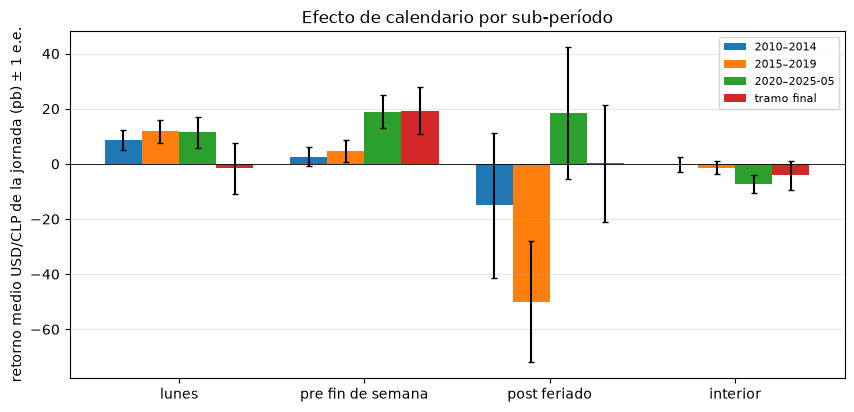

Años en que 'lunes + pre fin de semana' supera al resto: 15 de 17


anio,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
grupo,,,,,,,,,,,,,,,,,
lunes + pre fin de semana,-3.5,7.8,7.9,8.7,8.4,23.2,6.5,-1.2,9.6,2.6,10.5,16.7,19.0,20.5,11.3,13.6,4.4
resto,-2.6,3.5,-19.6,1.7,3.5,-4.5,-8.4,-5.7,2.8,4.0,-11.5,2.2,-10.3,-11.6,1.7,-16.4,3.8


In [9]:
# estabilidad por sub-período
dfc = pd.DataFrame({"r": F["ret_next"], "c": cat}).dropna()
periodos = [("2010-01-01", "2014-12-31", "2010–2014"), ("2015-01-01", "2019-12-31", "2015–2019"),
            ("2020-01-01", "2025-05-29", "2020–2025-05"), ("2025-05-30", "2030-01-01", "tramo final")]
fig, ax = plt.subplots(figsize=(10, 4.5))
w = 0.2
for i, (a, b, nom) in enumerate(periodos):
    s = dfc[(dfc.index >= a) & (dfc.index <= b)]
    g = s.groupby("c")["r"]
    medias = (g.mean() * 1e4).reindex(ORDEN)
    errs = (g.std() / np.sqrt(g.size()) * 1e4).reindex(ORDEN)
    ax.bar(np.arange(4) + (i - 1.5) * w, medias.values, w, yerr=errs.values, capsize=2, label=nom)
ax.axhline(0, color="k", lw=.6); ax.set_xticks(range(4)); ax.set_xticklabels(["lunes", "pre fin de semana", "post feriado", "interior"])
ax.set_ylabel("retorno medio USD/CLP de la jornada (pb) ± 1 e.e."); ax.set_title("Efecto de calendario por sub-período")
ax.legend(fontsize=8); ax.grid(alpha=.3, axis="y"); plt.show()

anual = dfc[(dfc.index >= "2010-01-01")].assign(anio=lambda d: d.index.year, grupo=lambda d: np.where(d["c"].isin(["lunes", "pre_finde"]), "lunes + pre fin de semana", "resto"))
anual = anual.groupby(["anio", "grupo"])["r"].mean().unstack() * 1e4
print(f"Años en que 'lunes + pre fin de semana' supera al resto: {int((anual.iloc[:, 0] > anual.iloc[:, 1]).sum())} de {len(anual)}")
display(anual.round(1).T)

## 6. Backtest: curvas, retornos por año y caídas

Las curvas muestran el excedente acumulado sobre la tasa en pesos (en % del nocional), neto de carry y de 6 pb por unidad; la línea punteada es la estrategia antes de costos. El panel inferior es la exposición vigente en cada jornada.

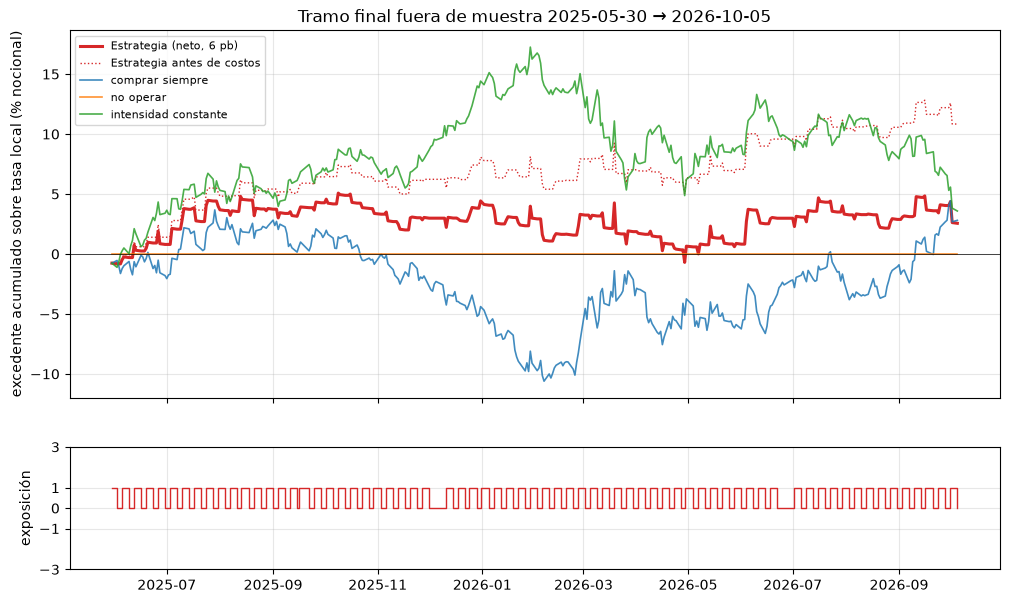

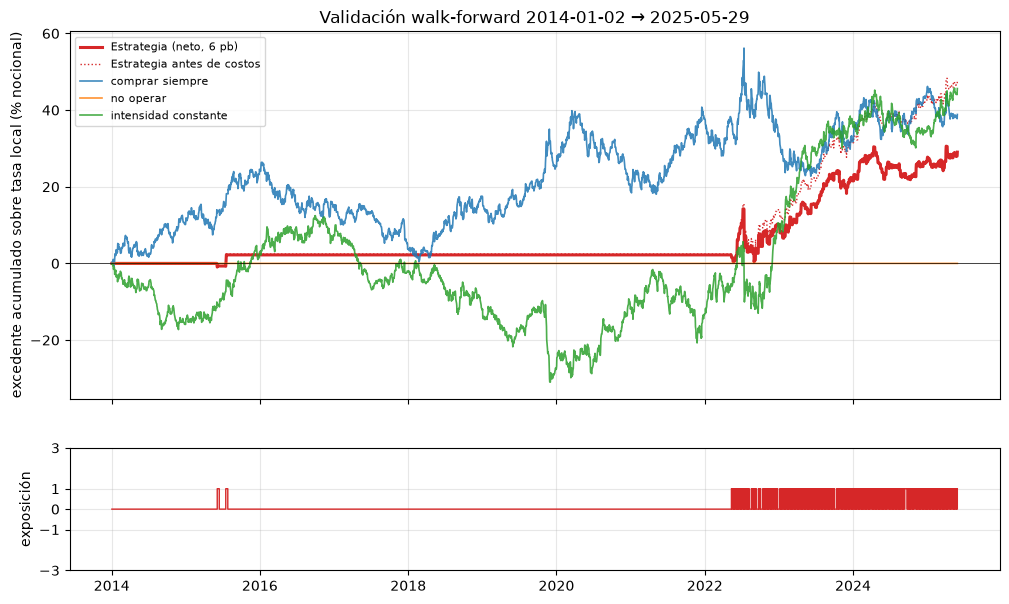

In [10]:
def grafico(est, pos, refs, titulo):
    fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    ax[0].plot(est.index, est["neto"].cumsum() * 100, lw=2.2, color="C3", label=f"Estrategia (neto, {COSTO:.0f} pb)")
    ax[0].plot(est.index, est["con_carry"].cumsum() * 100, lw=1, ls=":", color="C3", label="Estrategia antes de costos")
    for k, v in refs.items():
        ax[0].plot(v.index, v["neto"].cumsum() * 100, lw=1.2, alpha=.85, label=k.replace("_", " "))
    ax[0].axhline(0, color="k", lw=.5); ax[0].set_ylabel("excedente acumulado sobre tasa local (% nocional)")
    ax[0].set_title(titulo); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
    ax[1].step(pos.index, pos.values, where="post", lw=1, color="C3")
    ax[1].set_yticks([-3, -1, 0, 1, 3]); ax[1].set_ylabel("exposición"); ax[1].grid(alpha=.3)
    plt.show()


grafico(est_f, pos_wf.loc[est_f.index], refs_f, f"Tramo final fuera de muestra {est_f.index[0].date()} → {est_f.index[-1].date()}")
grafico(est_v, pos_wf.loc[est_v.index], refs_v, f"Validación walk-forward {est_v.index[0].date()} → {est_v.index[-1].date()}")

Retorno neto por año (%, excedente sobre la tasa local; 2026 hasta el fin de la base):


fecha,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
estrategia,0.00,2.22,0.00,0.00,0.00,0.00,0.00,0.00,7.95,11.41,4.93,6.95,-1.87
comprar siempre,10.19,14.37,-9.39,-11.43,13.28,8.54,-6.53,18.88,-3.94,-2.26,13.18,-10.42,7.19
intensidad constante,-15.92,18.74,4.58,-9.48,-9.57,-16.00,15.74,-1.46,22.99,27.07,-2.22,25.56,-10.83
jornadas con posición,0.00,4.00,0.00,0.00,0.00,0.00,0.00,0.00,60.00,102.00,104.00,103.00,77.00
episodios,0.00,2.00,0.00,0.00,0.00,0.00,0.00,0.00,30.00,51.00,51.00,52.00,38.00


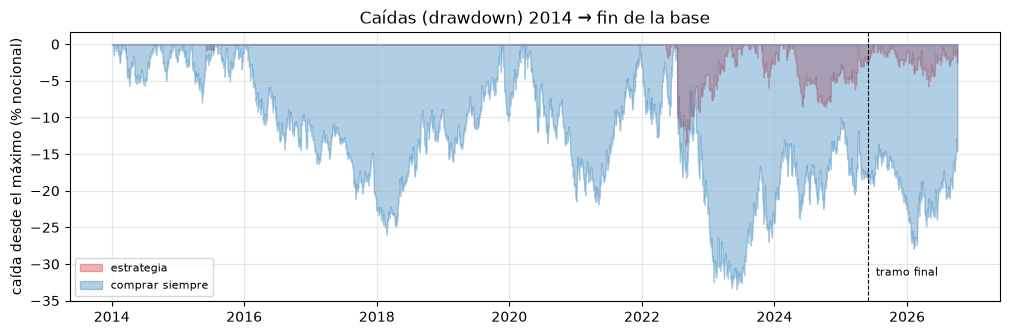

In [11]:
# retornos netos por año (excedente sobre la tasa local, %) y caídas
todo_est = pd.concat([est_v, est_f])
todo_refs = {k: pd.concat([refs_v[k], refs_f[k]]) for k in refs_v}
por_anio = pd.DataFrame({"estrategia": todo_est["neto"], "comprar siempre": todo_refs["comprar_siempre"]["neto"],
                         "intensidad constante": todo_refs["intensidad_constante"]["neto"]})
por_anio = (por_anio.groupby(por_anio.index.year).sum() * 100).round(2)
por_anio["jornadas con posición"] = todo_est["pos"].ne(0).groupby(todo_est.index.year).sum()
por_anio["episodios"] = (todo_est["pos"].ne(0) & ~todo_est["pos"].ne(0).shift(1, fill_value=False)).groupby(todo_est.index.year).sum()
print("Retorno neto por año (%, excedente sobre la tasa local; 2026 hasta el fin de la base):")
display(por_anio.T)

fig, ax = plt.subplots(figsize=(12, 3.5))
for nombre, serie, color in [("estrategia", todo_est["neto"], "C3"), ("comprar siempre", todo_refs["comprar_siempre"]["neto"], "C0")]:
    acum = serie.cumsum()
    ax.fill_between(acum.index, (acum - acum.cummax()) * 100, 0, alpha=.35, color=color, label=nombre)
ax.axvline(pd.Timestamp(INICIO_TEST), color="k", ls="--", lw=.8); ax.text(pd.Timestamp(INICIO_TEST), ax.get_ylim()[0] * .9 if ax.get_ylim()[0] < 0 else -1, "  tramo final", fontsize=8)
ax.set_ylabel("caída desde el máximo (% nocional)"); ax.set_title("Caídas (drawdown) 2014 → fin de la base"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.show()

**Período activo.** La tabla anual muestra que la regla estuvo fuera del mercado entre 2014 y 2021 (salvo cuatro jornadas en 2015): el lunes era la única categoría activa y un lunes aislado no cubre el umbral económico; la jornada previa al fin de semana cruzó los umbrales de la ventana expansiva en 2022. La celda siguiente repite las estadísticas desde la primera jornada operada de 2022 hasta el final de la validación. La ventana se define por actividad de la regla, no por su resultado, y sirve para leer el Sharpe y la volatilidad sin la dilución de ocho años en cero.

In [12]:
inicio_activo = est_v.index[(est_v["pos"] != 0) & (est_v.index >= "2022-01-01")][0]
est_a, refs_a = tramo(str(inicio_activo.date()), FIN_VAL)
print(f"Validación, período activo {inicio_activo.date()} → {est_a.index[-1].date()} ({len(est_a)} jornadas):")
display(tabla_estadisticas(est_a, refs_a).loc[["retorno neto de carry y costos (%)", "retorno neto anualizado (%)", "volatilidad anualizada (%)",
                                               "Sharpe anualizado (excedente sobre la TPM)", "Sortino", "caída máxima (%)",
                                               "% aciertos en jornadas operadas (sin apalancamiento)", "nº operaciones (cambios de exposición)",
                                               "nº episodios (entrada → salida)", "% jornadas fuera del mercado"]])

Validación, período activo 2022-05-12 → 2025-05-29 (774 jornadas):


,estrategia,comprar siempre,no operar,intensidad constante
retorno neto de carry y costos (%),26.81,1.24,0.0,51.00
retorno neto anualizado (%),8.73,0.40,0.0,16.60
volatilidad anualizada (%),10.75,16.02,0.0,15.85
Sharpe anualizado (excedente sobre la TPM),0.81,0.03,0.0,1.05
Sortino,1.19,0.04,NaN,1.50
caída máxima (%),-13.87,-33.43,0.0,-18.67
% aciertos en jornadas operadas (sin apalancamiento),58.58,50.39,NaN,56.12
nº operaciones (cambios de exposición),307.00,1.00,0.0,322.00
nº episodios (entrada → salida),154.00,1.00,0.0,7.00
% jornadas fuera del mercado,60.08,0.00,100.0,0.78


En el período activo la referencia de intensidad constante rinde más que la estrategia (vende dólar martes a jueves, jornadas que en 2020 → 2025 promediaron −7 pb), a costa de una caída máxima mayor y de 24 pb de costos por semana en lugar de 12. La regla no toma esa pata corta porque la jornada interior no supera los umbrales declarados sobre la muestra completa (−3 pb, t ≈ −2) y porque, con la media estimada por la ventana expansiva (≈ −4 pb), una racha de tres jornadas interiores (≈ 12 pb) no cubre 15 pb; en el tramo final esa decisión costó ≈ 1 punto de retorno y evitó más del doble de caída máxima. Es una elección de diseño declarada antes de ver el tramo final, no un ajuste posterior.

## 7. Pruebas estadísticas y sensibilidad

**Diebold-Mariano** (pérdida = −resultado neto diario; corrección de Harvey-Leybourne-Newbold; varianza Newey-West) y **bootstrap estacionario** de Politis-Romano (bloque medio 10 jornadas, 5.000 réplicas) sobre la diferencia diaria de resultado neto entre la estrategia y cada referencia. Un DM negativo favorece a la estrategia (menor pérdida); un DM positivo favorece a la referencia.

In [13]:
def pruebas(est, refs, etiqueta):
    filas = []
    for k, v in refs.items():
        d = diebold_mariano(-est["neto"], -v["neto"])
        bs = ic_bootstrap(est["neto"] - v["neto"], B=5000, bloque=10)
        filas.append({"tramo": etiqueta, "frente a": k.replace("_", " "), "diferencia neta (%)": round(bs["observado_%"], 2),
                      "DM (HLN)": round(d["DM_HLN"], 2), "p-valor DM": round(d["p_valor"], 3),
                      "IC95 bootstrap (%)": f"[{bs['ic95_%'][0]:+.2f}, {bs['ic95_%'][1]:+.2f}]", "P(diferencia > 0)": round(bs["p_mayor_que_0"], 2)})
    return pd.DataFrame(filas)


display(pd.concat([pruebas(est_v, refs_v, f"validación ({len(est_v)} jornadas)"), pruebas(est_f, refs_f, f"tramo final ({len(est_f)} jornadas)")]).set_index(["tramo", "frente a"]))

diferencia neta (%)  DM (HLN)  p-valor DM IC95 bootstrap (%)  P(diferencia > 0)
tramo                      frente a                                                                                             
validación (2878 jornadas) comprar siempre                     -9.83      0.26       0.794   [-83.16, +62.15]               0.40
                           no operar                           29.03     -1.58       0.115    [-4.21, +64.60]               0.95
                           intensidad constante               -16.59      0.42       0.671   [-91.83, +58.58]               0.34
tramo final (341 jornadas) comprar siempre                     -0.25      0.03       0.980   [-19.52, +18.17]               0.50
                           no operar                            2.56     -0.36       0.716    [-9.63, +14.61]               0.66
                           intensidad constante                -1.03      0.10       0.918   [-20.08, +18.52]               0.46

In [14]:
# sensibilidad al costo por unidad (neto %, Sharpe, caída máxima) y a los parámetros de la regla
m_v = (pos_wf.index >= INICIO_VAL) & (pos_wf.index <= FIN_VAL) & F["ret_next"].notna()
m_f = (pos_wf.index >= INICIO_TEST) & F["ret_next"].notna()
costos = pd.concat({"validación": tabla_costos(pos_wf[m_v], F).set_index("costo_pb"), "tramo final": tabla_costos(pos_wf[m_f], F).set_index("costo_pb")}, axis=1)
print("Sensibilidad al costo por unidad de cambio de exposición (pb):"); display(costos)

filas = []
for t_min in (1.5, 2.0, 2.5):
    for margen in (1.0, 1.25, 1.5):
        p_, _ = estrategia_calendario(F, INICIO_REGLA, 0.0, 0.25, COSTO, t_min=t_min, margen=margen)
        for mm, nom in [(m_v, "validación"), (m_f, "tramo final")]:
            r = resumen(pnl(p_[mm], F, COSTO))
            filas.append({"t activación": t_min, "margen sobre costo": margen, "tramo": nom, "neto (%)": round(r["neto_%"], 2),
                          "Sharpe": round(r["sharpe_neto_anual"], 2), "caída máx. (%)": round(r["max_drawdown_%"], 2), "nº operaciones": r["n_operaciones"]})
sens = pd.DataFrame(filas).pivot_table(index=["t activación", "margen sobre costo"], columns="tramo", values=["neto (%)", "Sharpe", "nº operaciones"])
print("\nSensibilidad a los parámetros de la regla (la configuración usada es t = 2,0 y margen 1,25):"); display(sens.round(2))

# lectura congelada: la tabla de ventajas vigente al 2025-05-29 aplicada sin re-estimar al tramo final
pos_cg, _ = estrategia_calendario(F, INICIO_REGLA, 0.0, 0.25, COSTO, congelar_desde=INICIO_TEST)
r_cg = resumen(pnl(pos_cg[m_f], F, COSTO))
print(f"\nTramo final con la tabla congelada al 2025-05-29: neto {r_cg['neto_%']:.2f} %, Sharpe {r_cg['sharpe_neto_anual']:.2f} "
      f"(walk-forward: {tab_f.loc['retorno neto de carry y costos (%)', 'estrategia']:.2f} %, {tab_f.loc['Sharpe anualizado (excedente sobre la TPM)', 'estrategia']:.2f}); "
      f"posiciones distintas en {int((pos_cg[m_f] != pos_wf[m_f]).sum())} jornadas")

Sensibilidad al costo por unidad de cambio de exposición (pb):


validación                              tramo final                             
             neto_% neto_anual_% sharpe max_dd_%      neto_% neto_anual_% sharpe max_dd_%
costo_pb                                                                                 
0             47.69         4.18   0.74   -13.03       10.84         8.01   1.06    -4.24
2             41.47         3.63   0.64   -13.31        8.08         5.97   0.79    -4.48
5             32.14         2.81   0.50   -13.73        3.94         2.91   0.39    -5.22
6             29.03         2.54   0.45   -13.87        2.56         1.89   0.25    -5.78
7             25.92         2.27   0.40   -14.01        1.18         0.87   0.12    -6.34
10            16.59         1.45   0.26   -14.43       -2.96        -2.19  -0.29    -8.39


Sensibilidad a los parámetros de la regla (la configuración usada es t = 2,0 y margen 1,25):


Sharpe               neto (%)            nº operaciones           
tramo                           tramo final validación tramo final validación    tramo final validación
t activación margen sobre costo                                                                        
1.5          1.00                      0.25       0.45        2.56      29.03          138.0      311.0
             1.25                      0.25       0.45        2.56      29.03          138.0      311.0
             1.50                      0.25      -0.11        2.56      -3.54          138.0      135.0
2.0          1.00                      0.25       0.45        2.56      29.03          138.0      311.0
             1.25                      0.25       0.45        2.56      29.03          138.0      311.0
             1.50                      0.25      -0.11        2.56      -3.54          138.0      135.0
2.5          1.00                      0.25       0.32        2.56      13.25          138.0      213.0
             1.25                      0.25       0.32        2.56      13.25          138.0      213.0
             1.50                      0.25      -0.11        2.56      -3.54          138.0      135.0


Tramo final con la tabla congelada al 2025-05-29: neto 2.56 %, Sharpe 0.25 (walk-forward: 2.56 %, 0.25); posiciones distintas en 0 jornadas


Lectura de la sensibilidad: el resultado no cambia entre un t de activación de 1,5 y 2,0 ni entre un margen de 1,0 y 1,25 sobre el costo (umbral de 12 o 15 pb por episodio); con margen 1,5 el umbral (18 pb) iguala la ventaja esperada de la racha viernes + lunes (≈ 18–20 pb) y la regla casi deja de operar. La estrategia trabaja, por lo tanto, con una ventaja de alrededor de 1,5 veces el costo de ida y vuelta: suficiente para operar con exposición 1, insuficiente para justificar más tamaño o más rotación.

## 8. Lectura de la convicción (entregable 3 de las bases)

La convicción de la regla es la ventaja esperada de la categoría de la jornada objetivo y su respaldo estadístico. Para cada jornada la señal informa la categoría, la ventaja esperada en pb, el estadístico t de la categoría, la probabilidad de alza implícita (Φ(media/desviación) de la categoría) y el Sharpe diario esperado; la posición es 1 solo cuando la racha cubre el costo con margen. La tabla resume, en el tramo final, qué hizo la regla por tipo de jornada y cuánto rindió cada tipo.

In [17]:
lec = det_wf[m_f].assign(ret_real_pb=F.loc[m_f, "ret_next"] * 1e4)
tabla_lec = lec.groupby("categoria_prox").agg(jornadas=("pos", "size"), posicion_media=("pos", "mean"), ventaja_esperada_pb=("mu_pb", "mean"),
                                              media_historica_pb=("media_bruta_pb", "mean"), t_categoria=("t_cat", "mean"),
                                              retorno_real_pb=("ret_real_pb", "mean"), sharpe_diario_esperado=("sharpe_esperado", "mean")).reindex(ORDEN).round(2)
display(tabla_lec)
print("Distribución de posiciones en el tramo final:", {int(k): int(v) for k, v in pos_wf[m_f].value_counts().sort_index().items()})

,jornadas,posicion_media,ventaja_esperada_pb,media_historica_pb,t_categoria,retorno_real_pb,sharpe_diario_esperado
categoria_prox,,,,,,,
lunes,69,1.00,9.91,9.91,3.84,-1.67,0.13
pre_finde,70,0.97,8.61,8.61,3.25,19.23,0.11
post_feriado,2,0.00,NaN,NaN,NaN,0.17,NaN
interior,200,0.00,0.00,-4.11,-2.68,-4.21,0.00


Distribución de posiciones en el tramo final: {0: 204, 1: 137}


## 9. Mecanismo de ejecución (para replicar la estrategia en el monitor del laboratorio)

**Momento de decisión y precio.** La estrategia opera **al cierre**. Al cierre de cada jornada t se toma el último cierre disponible de `USDCLP Curncy PX_LAST` (y el resto de la fila t de la base) y se decide la exposición que regirá durante **toda la jornada siguiente t+1**. El resultado de t+1 se mide de cierre a cierre: `pos_t × (S_t+1 / S_t − 1)`. No se usa la apertura ni el dólar observado (el observado publicado con fecha t+1 corresponde al promedio de la jornada t).

**Qué gatilla cada operación.** Solo el calendario de la jornada objetivo y la tabla de ventajas por categoría estimada con información pasada (sección 3.2): se abre exposición +1 al inicio de una racha de jornadas con ventaja (viernes o víspera de feriado seguido de lunes) cuando la suma de ventajas esperadas de la racha es ≥ 15 pb; se mantiene mientras dure la racha; se cierra en la primera jornada sin ventaja. No hay otras órdenes, ni stops, ni cambios intradía.

**En la práctica, para el período de monitoreo (viernes 13-nov → martes 1-dic de 2026, sin feriados chilenos):** exposición **+1 en las jornadas de viernes y lunes** (compra de dólar al cierre del jueves, venta al cierre del lunes) y **0 de martes a jueves**. La posición de la primera jornada monitoreada (viernes 13-nov) se decide con el cierre del jueves 12-nov. La tabla se re-estima cada 21 jornadas; si una categoría cruzara su umbral de activación, la señal diaria cambiaría, de modo que la posición vinculante es la que emite `scripts/predict_next.py` cada día con la base actualizada. La celda siguiente imprime la proyección completa del período.

**Contabilización de cada operación.** Costo de 6 pb por unidad de cambio de exposición, cargado en la jornada en que rige la nueva exposición (entrar y salir: 12 pb por episodio). Carry: `pos × (TPM − SOFR) / 360 × días corridos` entre t y t+1 (de viernes a lunes: 3 días). En feriados chilenos no hay jornada: la posición se mantiene y las tasas se devengan por días corridos.

**Comando diario** (al cierre, con la base actualizada por el laboratorio):

```
python scripts/predict_next.py data/base_usdclp.xlsx
```

Devuelve un JSON con la fecha de información, la jornada objetivo, su categoría, la probabilidad de alza, la ventaja esperada, el estadístico t, la posición sugerida y una lectura en palabras. Cada señal emitida se registra en `reports/bitacora_vivo.md`. Con una fecha como segundo argumento el script responde como si la base terminara ese día (útil para auditar); con `--calendario desde hasta` imprime la proyección de un período.

In [18]:
print("Señal del día con la base completa (información hasta la última jornada):")
senal = generar_senal(base)
for k, v in senal.items():
    print(f"  {k:28s} {v}")

print("\nEjemplos auditables: con información hasta el jueves 2026-10-01 (jornada objetivo viernes 02-10) y hasta el lunes 2026-10-05 (objetivo martes 06-10):")
for d in ["2026-10-01", "2026-10-05"]:
    s = generar_senal(base, hasta=d)
    print(f"  {s['fecha_informacion']} → {s['jornada_objetivo']} ({s['categoria_jornada_objetivo']:12s}) posición {s['posicion_sugerida']:+d} | ventaja {s['ventaja_esperada_pb']:+.1f} pb, t {s['t_categoria']}, prob. alza {s['prob_alza']}")

print(f"\nProyección para el período de monitoreo 2026-11-13 → 2026-12-01 (tabla de ventajas vigente al {base.index[-1].date()}; feriados considerados: {FERIADOS_CL}):")
display(calendario_esperado(base, "2026-11-13", "2026-12-01"))

Señal del día con la base completa (información hasta la última jornada):
  fecha_informacion            2026-10-06
  jornada_objetivo             2026-10-07
  categoria_jornada_objetivo   interior
  cierre_usdclp                973.95
  direccion                    baja
  prob_alza                    0.479
  ventaja_esperada_pb          0.0
  t_categoria                  -2.66
  sharpe_esperado_diario       0.0
  posicion_sugerida            0
  lectura                      Sin posición: la jornada objetivo es jornada interior de la semana; la ventaja histórica de esa categoría no supera el umbral estadístico (|t| > 2) o la ventaja acumulada de la racha de jornadas con ventaja no cubre 1,25 veces el costo de ida y vuelta (12 pb). Quedarse en pesos ganando la tasa local.

Ejemplos auditables: con información hasta el jueves 2026-10-01 (jornada objetivo viernes 02-10) y hasta el lunes 2026-10-05 (objetivo martes 06-10):
  2026-10-01 → 2026-10-02 (pre_finde   ) posición +1 | ventaja +8.9

,fecha_informacion,jornada_objetivo,dia,categoria,ventaja_esperada_pb,posicion
0,2026-11-12,2026-11-13,Fri,pre_finde,8.9,1
1,2026-11-13,2026-11-16,Mon,lunes,9.4,1
2,2026-11-16,2026-11-17,Tue,interior,0.0,0
3,2026-11-17,2026-11-18,Wed,interior,0.0,0
4,2026-11-18,2026-11-19,Thu,interior,0.0,0
5,2026-11-19,2026-11-20,Fri,pre_finde,8.9,1
6,2026-11-20,2026-11-23,Mon,lunes,9.4,1
7,2026-11-23,2026-11-24,Tue,interior,0.0,0
8,2026-11-24,2026-11-25,Wed,interior,0.0,0
9,2026-11-25,2026-11-26,Thu,interior,0.0,0


## 10. Riesgos, limitaciones y reproducibilidad

- **Ventaja delgada frente a los costos.** La racha viernes + lunes tiene ≈ 18–20 pb esperados contra 12 pb de ida y vuelta; el punto de equilibrio del tramo final está en ≈ 8 pb por unidad y el de la validación en ≈ 15 pb (sección 7). Por eso la exposición es 1, solo en rachas que cubren el costo con margen, y por eso las estrategias de alta rotación (incluida la referencia de intensidad constante) no sobreviven a costos realistas.
- **Riesgo de régimen.** El efecto del lunes es el histórico de las monedas emergentes y no apareció en el tramo final (−1,7 pb); el de la jornada previa al fin de semana, que sostiene el resultado fuera de muestra (+19 pb), es específico del peso chileno y reciente (2020 en adelante). La regla se desactiva sola si el estadístico t de una categoría cae bajo 1, pero con cientos de observaciones por categoría la ventana expansiva reacciona con lentitud: puede seguir operando un efecto que ya se apagó, o tardar en recoger uno nuevo, durante meses. Es el principal riesgo de la estrategia y lo declaramos.
- **Nada es estadísticamente significativo con 341 jornadas** (p > 0,6 frente a todas las referencias) y es marginal en la validación (p = 0,115 frente a no operar). No vendemos el tramo final como prueba; vendemos el método, el perfil de riesgo y la honestidad de la evaluación.
- **Reproducibilidad.** `python scripts/run_final.py data/base_usdclp.xlsx reports` genera las mismas cifras, los gráficos y `reports/final_resumen.json`; `python tests/test_no_leakage.py data/base_usdclp.xlsx` verifica que las posiciones no cambian al barajar el futuro, que están en {−3, −1, 0, 1, 3}, que el P&L paga la posición con el retorno de la jornada siguiente y que las variables no dependen de filas futuras. Semillas fijas; `requirements.txt` con las versiones mínimas.